⏳ Đang tải dữ liệu ETHUSDT khung 1h...
✅ Data ready...
🚀 Running Dual KC(20/15) + RSI(40 WeightedClose) Strategy...

🎯 STRATEGY - Dual KC(20/15) + RSI(40 WeightedClose) + STOP + ATR buffer + SL(ATR20) TP(ATR25)
     Final Equity: 14599.9291
     Total Return: 0.4600
    CAGR (approx): 0.1925
     Max Drawdown: -0.0939
           Sharpe: 1.6377
           Trades: 258
          Winrate: 0.5814
    Avg PnL/Trade: 17.5445
    Profit Factor: 1.3410

💡 Estimated R:R: 1:0.97


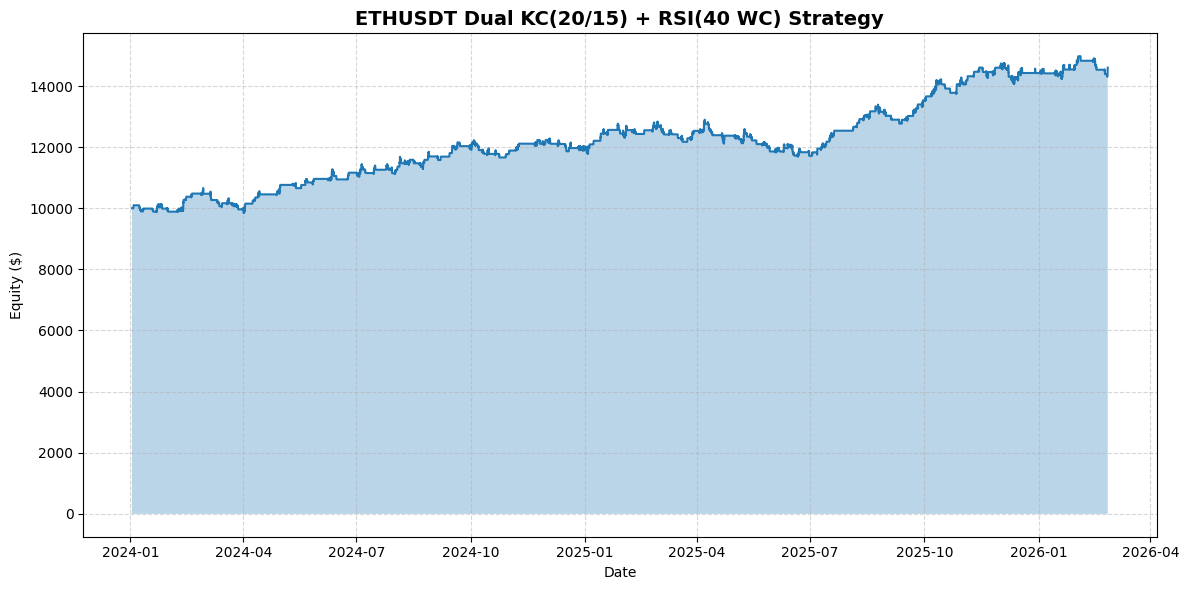


📊 Sample Trades:
            Exit Time   Type        Entry         Exit         PnL       Reason       Balance
0 2024-01-03 14:00:00  SHORT  2248.550000  2191.190218   96.938032  Take Profit  10096.938032
1 2024-01-08 07:00:00  SHORT  2183.547002  2229.335124 -100.733869    Stop Loss   9996.204164
2 2024-01-09 12:00:00   LONG  2335.980000  2275.639921  -99.561130    Stop Loss   9896.643034
3 2024-01-11 14:00:00   LONG  2560.959765  2672.634720   92.690213  Take Profit   9989.333247
4 2024-01-19 10:00:00  SHORT  2439.500000  2494.056702  -99.838766    Stop Loss   9889.494481
5 2024-01-22 08:00:00  SHORT  2432.168281  2399.500015  101.598306  Take Profit   9991.092787
6 2024-01-22 19:00:00  SHORT  2389.310000  2350.326156   97.849449  Take Profit  10088.942237
7 2024-01-26 16:00:00  SHORT  2216.110000  2276.265462 -100.459621    Stop Loss   9988.482615
8 2024-01-31 09:00:00   LONG  2370.300000  2320.877933  -99.832575    Stop Loss   9888.650040
9 2024-02-08 15:00:00   LONG  2418.180000 

In [1]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# =========================================================
# 1) HÀM TẢI DỮ LIỆU BINANCE
# =========================================================
def str_to_millis(date_str: str) -> int:
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol: str, interval: str, start_str: str, end_str: str) -> pd.DataFrame:
    base_url = "https://api.binance.com/"
    api_url = "api/v3/klines"
    general_url = base_url + api_url

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Đang tải dữ liệu {symbol} khung {interval}...")

    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        try:
            response = requests.get(general_url, params=params, timeout=10)
            if response.status_code != 200:
                print("Error:", response.status_code, response.text)
                break
            data = response.json()
            if not data:
                break
            all_klines.extend(data)
            last_ts = data[-1][0]
            start_time = last_ts + 1
            time.sleep(0.05)
        except Exception as e:
            print(f"Lỗi: {e}")
            break

    if not all_klines:
        return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "Open", "High", "Low", "Close", "Volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df


# =========================================================
# 2) INDICATORS (WEIGHTED_CLOSE + RSI40 + KC20/KC15 + ATR20/25)
# =========================================================
def calculate_indicators(df: pd.DataFrame) -> pd.DataFrame:
    data = df.copy()

    # WEIGHTED_CLOSE (TradingView style): (H+L+2C)/4
    data["Weighted_Close"] = (data["High"] + data["Low"] + 2.0 * data["Close"]) / 4.0

    # True Range
    prev_close = data["Close"].shift(1)
    data["TR"] = pd.concat([
        (data["High"] - data["Low"]),
        (data["High"] - prev_close).abs(),
        (data["Low"] - prev_close).abs()
    ], axis=1).max(axis=1)

    # ATR (Wilder EMA style)
    def calc_atr(tr: pd.Series, period: int) -> pd.Series:
        return tr.ewm(alpha=1/period, min_periods=period, adjust=False).mean()

    data["ATR_20"] = calc_atr(data["TR"], 20)
    data["ATR_25"] = calc_atr(data["TR"], 25)

    # RSI (SMA rolling mean như template)
    def calc_rsi(series: pd.Series, period: int) -> pd.Series:
        delta = series.diff()
        gain = delta.where(delta > 0, 0.0).rolling(window=period).mean()
        loss = (-delta.where(delta < 0, 0.0)).rolling(window=period).mean()
        rs = gain / loss
        return 100 - (100 / (1 + rs))

    # RSI(40) on WEIGHTED_CLOSE
    data["RSI_40_WC"] = calc_rsi(data["Weighted_Close"], 40)

    # Keltner Channel:
    # KC(20, dev=2.3) using EMA(Close,20) ± dev*ATR(20)
    data["EMA_20"] = data["Close"].ewm(span=20, adjust=False).mean()
    data["KC_Upper_20"] = data["EMA_20"] + (2.3 * data["ATR_20"])
    data["KC_Lower_20"] = data["EMA_20"] - (2.3 * data["ATR_20"])

    # KC(15, dev=1.5) using EMA(Close,15) ± dev*ATR(15)
    data["EMA_15"] = data["Close"].ewm(span=15, adjust=False).mean()
    data["ATR_15"] = calc_atr(data["TR"], 15)
    data["KC_Upper_15"] = data["EMA_15"] + (1.5 * data["ATR_15"])
    data["KC_Lower_15"] = data["EMA_15"] - (1.5 * data["ATR_15"])

    # Highest/Lowest WEIGHTED_CLOSE lookback PeriodParam=14
    data["Highest_WC_14"] = data["Weighted_Close"].rolling(window=14).max()
    data["Lowest_WC_14"] = data["Weighted_Close"].rolling(window=14).min()

    data.dropna(inplace=True)
    return data


# =========================================================
# 3) BACKTESTER (STOP orders + Expiration(2) + SL ATR20 + TP ATR25; no trailing, no time-exit)
# =========================================================
class DualKCRSIWeightedCloseBacktester:
    def __init__(self, df: pd.DataFrame, initial_balance: float = 10000.0):
        self.df = df
        self.initial_balance = float(initial_balance)
        self.balance = float(initial_balance)

        self.equity_curve = []
        self.trades = []

        self.position = None          # None / 'LONG' / 'SHORT'
        self.entry_price = 0.0
        self.sl = 0.0
        self.tp = 0.0
        self.qty = 0.0
        self.entry_bar_idx = 0

        self.pending_order = None     # {'type','price','sl_dist','tp_dist','expire_idx'}

        # ===== Params (ĐÚNG MÔ TẢ) =====
        self.period_param = 14
        self.atr_period_entry = 20
        self.price_entry_mult = 2.4
        self.pending_expiration = 2

        self.sl_coef = 3.0            # SL = 3 * ATR(20, shift=1)
        self.tp_coef = 3.0            # TP = 3 * ATR(25, shift=1)

        # No trailing, no ExitAfterBars
        self.use_time_exit = False

        # Money management
        self.risk_pct = 0.01
        self.mm_max_lots = 100.0
        self.mm_decimals = 2

    def run(self):
        indices = self.df.index

        for i in range(len(self.df)):
            bar = self.df.iloc[i]
            idx = indices[i]

            # -------------------------------------------------
            # A) QUẢN LÝ LỆNH ĐANG MỞ (SL/TP)
            # -------------------------------------------------
            if self.position is not None:
                # intrabar SL/TP
                if self.position == "LONG":
                    if bar["Low"] <= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue
                    if bar["High"] >= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue

                elif self.position == "SHORT":
                    if bar["High"] >= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue
                    if bar["Low"] <= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue

            # -------------------------------------------------
            # B) QUẢN LÝ PENDING ORDER (EXPIRATION + FILL)
            # -------------------------------------------------
            if self.position is None and self.pending_order is not None:
                if i >= self.pending_order["expire_idx"]:
                    self.pending_order = None
                else:
                    p_price = self.pending_order["price"]

                    if self.pending_order["type"] == "BUY_STOP" and bar["High"] >= p_price:
                        fill_price = max(p_price, bar["Open"])  # mô phỏng gap
                        self.open_position("LONG", fill_price, i,
                                           self.pending_order["sl_dist"],
                                           self.pending_order["tp_dist"])
                        self.pending_order = None

                    elif self.pending_order["type"] == "SELL_STOP" and bar["Low"] <= p_price:
                        fill_price = min(p_price, bar["Open"])  # mô phỏng gap
                        self.open_position("SHORT", fill_price, i,
                                           self.pending_order["sl_dist"],
                                           self.pending_order["tp_dist"])
                        self.pending_order = None

            # -------------------------------------------------
            # C) TÍN HIỆU VÀO LỆNH + ĐẶT STOP ORDER
            # -------------------------------------------------
            if self.position is None and self.pending_order is None:
                # cần i>=2 cho RSI shift=2 vs shift=1
                # cần i>=3 cho Highest/Lowest shift=3
                # KC dùng shift=1
                if i < 3:
                    self.append_equity(idx)
                    continue

                open0 = bar["Open"]

                # KC shift=1
                kc_up_20_1 = self.df.iloc[i-1]["KC_Upper_20"]
                kc_lo_20_1 = self.df.iloc[i-1]["KC_Lower_20"]
                kc_up_15_1 = self.df.iloc[i-1]["KC_Upper_15"]
                kc_lo_15_1 = self.df.iloc[i-1]["KC_Lower_15"]

                # RSI shift=2 vs shift=1 (đúng mô tả)
                rsi_2 = self.df.iloc[i-2]["RSI_40_WC"]
                rsi_1 = self.df.iloc[i-1]["RSI_40_WC"]

                long_signal = (
                    (open0 > kc_up_20_1) and
                    (rsi_2 < rsi_1) and
                    (open0 > kc_up_15_1)
                )

                short_signal = (
                    (open0 < kc_lo_20_1) and
                    (rsi_2 > rsi_1) and
                    (open0 < kc_lo_15_1)
                )

                if (not long_signal) and (not short_signal):
                    self.append_equity(idx)
                    continue

                # Entry formula:
                # Long: Highest(WC,14,shift=3) + 2.4*ATR(20,shift=1)
                # Short: Lowest(WC,14,shift=3) - 2.4*ATR(20,shift=1)
                highest_wc_shift3 = self.df.iloc[i-3]["Highest_WC_14"]
                lowest_wc_shift3  = self.df.iloc[i-3]["Lowest_WC_14"]

                atr_20_shift1 = self.df.iloc[i-1]["ATR_20"]  # ATRPeriod=20, shift=1

                # SL/TP distances:
                sl_dist = self.sl_coef * self.df.iloc[i-1]["ATR_20"]  # ATR20 shift=1
                tp_dist = self.tp_coef * self.df.iloc[i-1]["ATR_25"]  # ATR25 shift=1

                if long_signal:
                    entry_price = highest_wc_shift3 + (self.price_entry_mult * atr_20_shift1)
                    self.pending_order = {
                        "type": "BUY_STOP",
                        "price": float(entry_price),
                        "sl_dist": float(sl_dist),
                        "tp_dist": float(tp_dist),
                        "expire_idx": i + self.pending_expiration
                    }
                elif short_signal and (not long_signal):
                    entry_price = lowest_wc_shift3 - (self.price_entry_mult * atr_20_shift1)
                    self.pending_order = {
                        "type": "SELL_STOP",
                        "price": float(entry_price),
                        "sl_dist": float(sl_dist),
                        "tp_dist": float(tp_dist),
                        "expire_idx": i + self.pending_expiration
                    }

            # -------------------------------------------------
            # D) APPEND EQUITY
            # -------------------------------------------------
            self.append_equity(idx)

    def append_equity(self, idx):
        mtm = self.balance
        close_price = self.df.loc[idx, "Close"]
        if self.position == "LONG":
            mtm += (close_price - self.entry_price) * self.qty
        elif self.position == "SHORT":
            mtm += (self.entry_price - close_price) * self.qty
        self.equity_curve.append({"time": idx, "equity": mtm})

    def open_position(self, pos_type: str, price: float, bar_idx: int, sl_dist: float, tp_dist: float):
        self.position = pos_type
        self.entry_price = float(price)
        self.entry_bar_idx = int(bar_idx)

        if pos_type == "LONG":
            self.sl = self.entry_price - sl_dist
            self.tp = self.entry_price + tp_dist
        else:
            self.sl = self.entry_price + sl_dist
            self.tp = self.entry_price - tp_dist

        # Risk-based sizing: 1% balance based on initial SL distance
        risk_amount = self.balance * self.risk_pct
        sl_distance = abs(self.entry_price - self.sl)
        qty = (risk_amount / sl_distance) if sl_distance > 0 else 0.0

        qty = min(qty, self.mm_max_lots)
        qty = np.floor(qty * (10 ** self.mm_decimals)) / (10 ** self.mm_decimals)
        self.qty = float(qty)

    def close_position(self, price: float, time_idx, reason: str):
        price = float(price)
        if self.position == "LONG":
            pnl = (price - self.entry_price) * self.qty
        else:
            pnl = (self.entry_price - price) * self.qty

        self.balance += pnl
        self.trades.append({
            "Exit Time": time_idx,
            "Type": self.position,
            "Entry": self.entry_price,
            "Exit": price,
            "PnL": pnl,
            "Reason": reason,
            "Balance": self.balance
        })

        self.position = None
        self.qty = 0.0


# =========================================================
# 4) METRICS + PLOT
# =========================================================
def calculate_metrics(trades_df: pd.DataFrame, equity_data, initial_balance: float):
    eq_df = pd.DataFrame(equity_data)
    eq_df.set_index("time", inplace=True)
    eq_df = eq_df[~eq_df.index.duplicated(keep="last")]

    final_equity = eq_df["equity"].iloc[-1]
    total_return = (final_equity - initial_balance) / initial_balance

    days = (eq_df.index[-1] - eq_df.index[0]).days
    years = days / 365.25 if days > 0 else 0.0
    cagr = ((final_equity / initial_balance) ** (1/years) - 1) if years > 0 else 0.0

    running_max = eq_df["equity"].cummax()
    dd = (eq_df["equity"] - running_max) / running_max
    max_dd = dd.min()

    eq_df["returns"] = eq_df["equity"].pct_change()
    mean_ret = eq_df["returns"].mean()
    std_ret = eq_df["returns"].std()
    bars_per_year = (len(eq_df) / years) if years > 0 else 8760
    sharpe = (mean_ret / std_ret) * np.sqrt(bars_per_year) if std_ret != 0 else 0.0

    total_trades = len(trades_df)
    win_trades = len(trades_df[trades_df["PnL"] > 0])
    win_rate = win_trades / total_trades if total_trades > 0 else 0.0
    avg_pnl = trades_df["PnL"].mean() if total_trades > 0 else 0.0

    gross_profit = trades_df[trades_df["PnL"] > 0]["PnL"].sum()
    gross_loss = abs(trades_df[trades_df["PnL"] < 0]["PnL"].sum())
    profit_factor = (gross_profit / gross_loss) if gross_loss > 0 else 0.0

    return {
        "Final Equity": final_equity,
        "Total Return": total_return,
        "CAGR (approx)": cagr,
        "Max Drawdown": max_dd,
        "Sharpe": sharpe,
        "Trades": total_trades,
        "Winrate": win_rate,
        "Avg PnL/Trade": avg_pnl,
        "Profit Factor": profit_factor,
        "equity_df": eq_df
    }

def print_report_and_plot(metrics, symbol: str):
    print("\n" + "="*60)
    print("🎯 STRATEGY - Dual KC(20/15) + RSI(40 WeightedClose) + STOP + ATR buffer + SL(ATR20) TP(ATR25)")
    print("="*60)
    print(f"     Final Equity: {metrics['Final Equity']:.4f}")
    print(f"     Total Return: {metrics['Total Return']:.4f}")
    print(f"    CAGR (approx): {metrics['CAGR (approx)']:.4f}")
    print(f"     Max Drawdown: {metrics['Max Drawdown']:.4f}")
    print(f"           Sharpe: {metrics['Sharpe']:.4f}")
    print(f"           Trades: {metrics['Trades']}")
    print(f"          Winrate: {metrics['Winrate']:.4f}")
    print(f"    Avg PnL/Trade: {metrics['Avg PnL/Trade']:.4f}")
    print(f"    Profit Factor: {metrics['Profit Factor']:.4f}")
    print("="*60)

    rr = (metrics["Profit Factor"] * (1 - metrics["Winrate"])) / metrics["Winrate"] if metrics["Winrate"] > 0 else 0
    print(f"\n💡 Estimated R:R: 1:{rr:.2f}")

    eq_df = metrics["equity_df"]
    plt.figure(figsize=(12, 6))
    plt.plot(eq_df.index, eq_df["equity"], linewidth=1.5)
    plt.fill_between(eq_df.index, eq_df["equity"], alpha=0.3)

    plt.title(f"{symbol} Dual KC(20/15) + RSI(40 WC) Strategy", fontsize=14, fontweight="bold")
    plt.xlabel("Date")
    plt.ylabel("Equity ($)")
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()


# =========================================================
# 5) MAIN
# =========================================================
if __name__ == "__main__":
    symbol = "ETHUSDT"
    interval = "1h"
    start_date = "01/01/2024"
    end_date = "25/02/2026"

    df_raw = fetch_binance_kline_df(symbol, interval, start_date, end_date)

    if len(df_raw) > 300:
        print("✅ Data ready...")
        df_calc = calculate_indicators(df_raw)

        print("🚀 Running Dual KC(20/15) + RSI(40 WeightedClose) Strategy...")
        bt = DualKCRSIWeightedCloseBacktester(df_calc, initial_balance=10000.0)
        bt.run()

        trades_df = pd.DataFrame(bt.trades)

        if not trades_df.empty:
            metrics = calculate_metrics(trades_df, bt.equity_curve, bt.initial_balance)
            print_report_and_plot(metrics, symbol)

            print("\n📊 Sample Trades:")
            print(trades_df.head(10).to_string())

            print("\n📈 Exit Reasons:")
            print(trades_df["Reason"].value_counts())
        else:
            print("⚠️ No trades.")
    else:
        print("❌ Insufficient data.")
